# Face-lab — facial expression branch
FER2013 expression model (EfficientNet-B0 v1) as an **independent late-fusion branch**: it only reads the face crop and only feeds the speech layer. An expression category is what the face shows, not a diagnosis of a feeling.

## 1 · Architecture

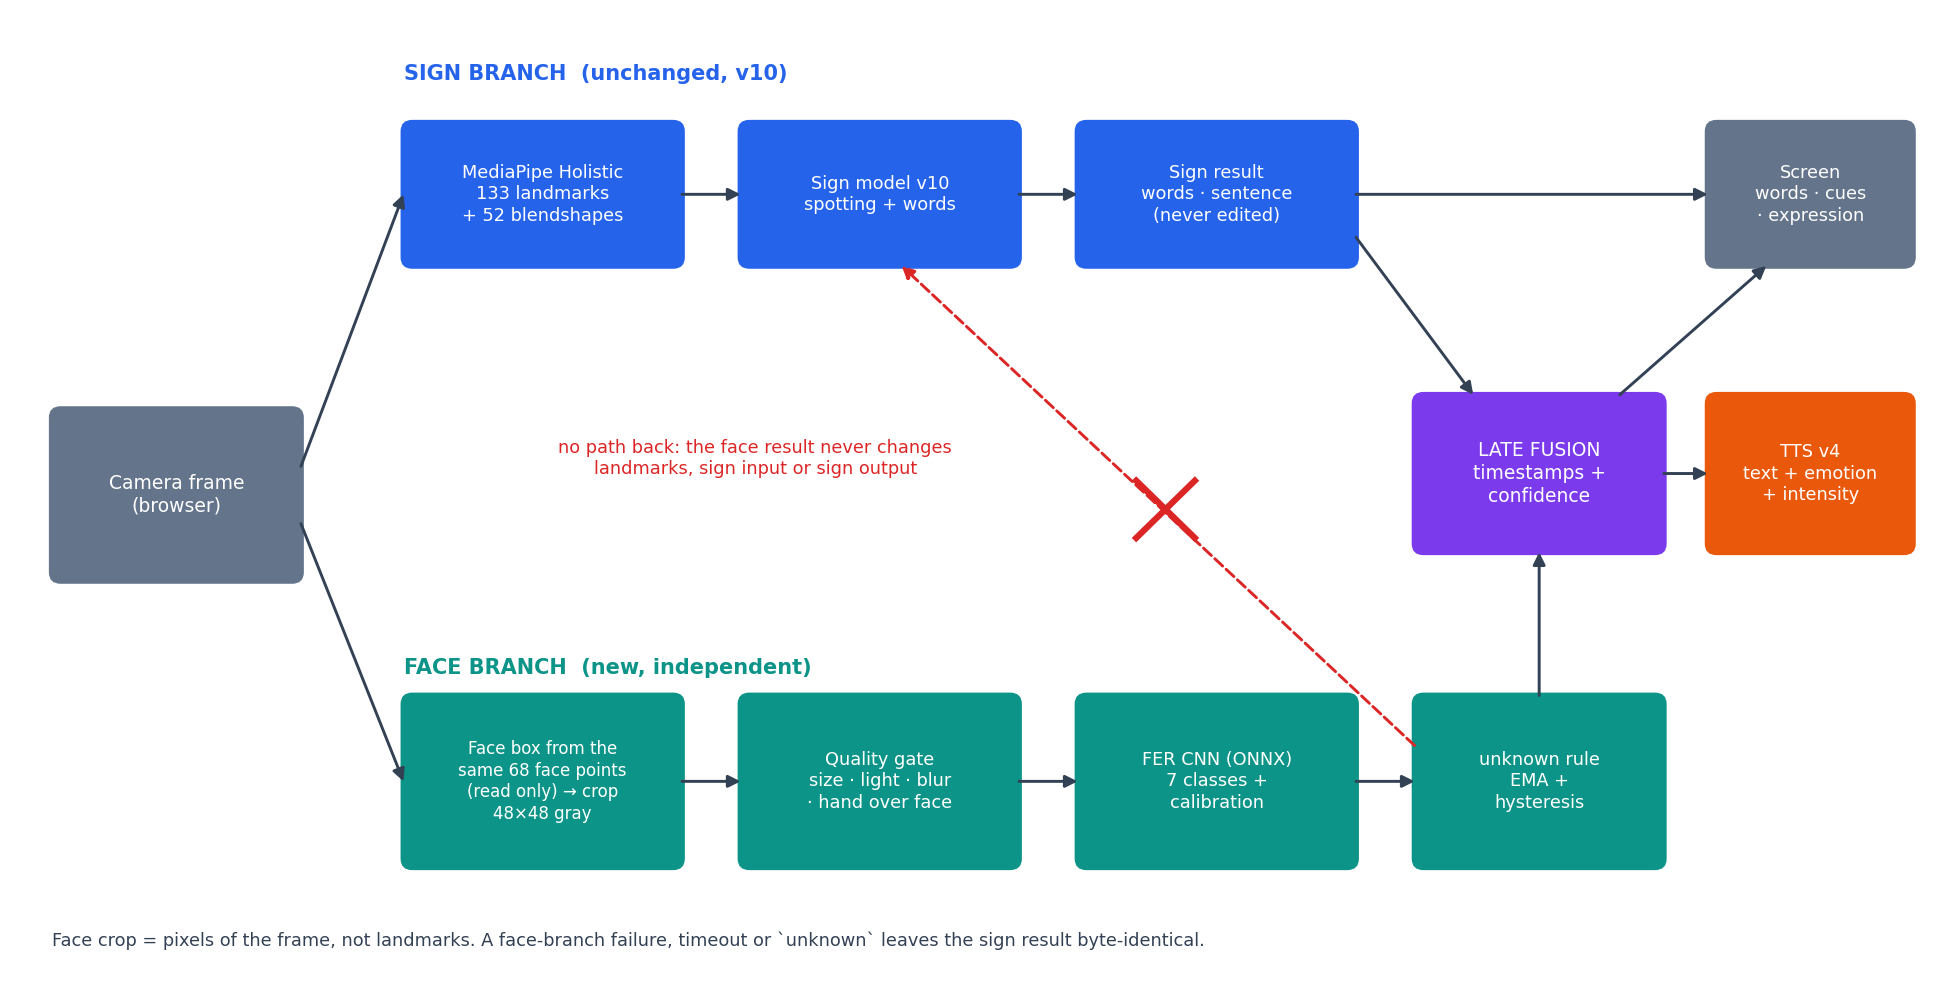

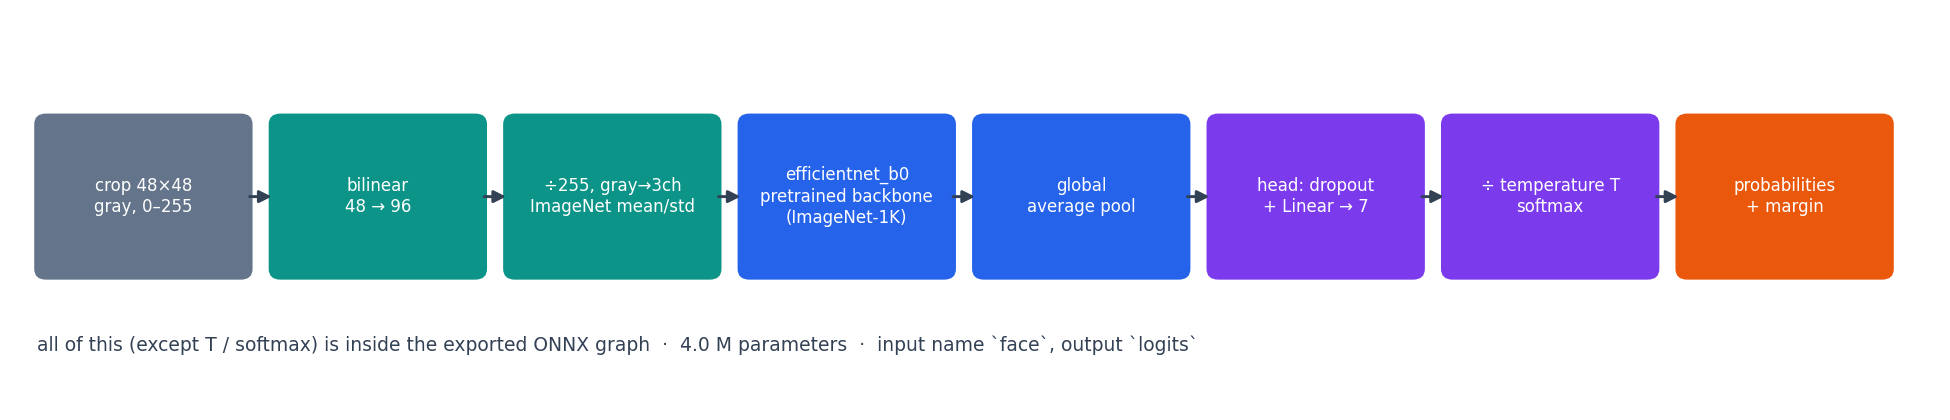

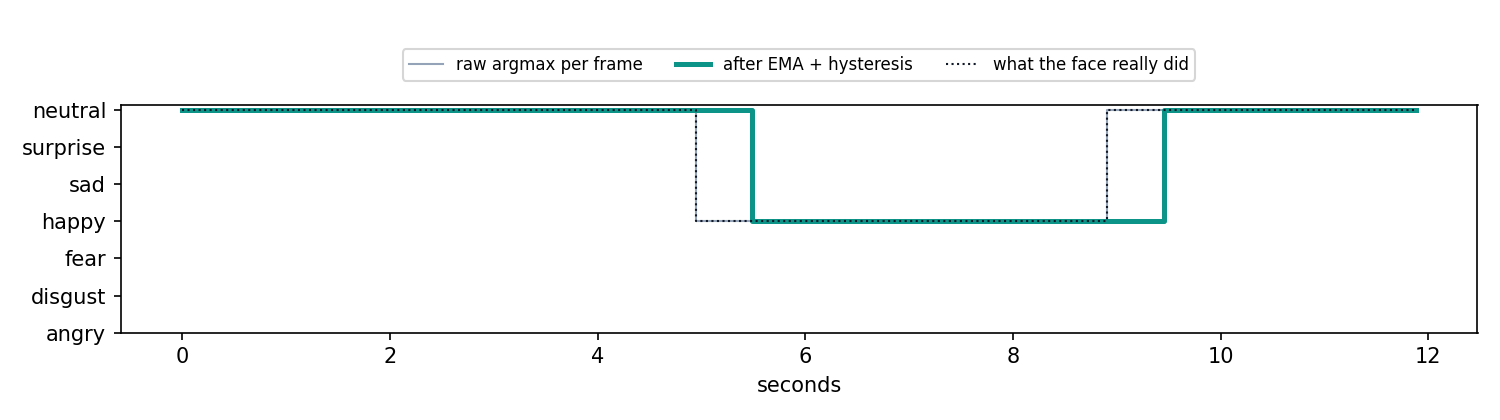

In [1]:
from IPython.display import Image, display
for f in ("architecture", "model_graph", "smoothing"):
    display(Image(f"figures/{f}.png"))

## 2 · Setup

In [2]:
import json, sys, time
from pathlib import Path
import numpy as np, matplotlib.pyplot as plt
import data, evaluate as ev
plt.rcParams["font.family"] = ["Leelawadee UI", "Tahoma", "DejaVu Sans"]      # Thai clip names
import demo
from data import CLASSES

D = data.prepare(42)
Xte, yte = D["test"]; clean = D["clean_test"]
MODEL = demo.find_model()
import onnxruntime as ort
sess = ort.InferenceSession(str(MODEL / "face_fer.onnx"), providers=["CPUExecutionProvider"])
cfg = json.load(open(MODEL / "config.json"))
def predict(X, T=cfg["temperature"]):
    z = np.concatenate([sess.run(None, {"face": X[i:i+256, None].astype(np.float32)})[0] for i in range(0, len(X), 256)])
    return ev.softmax(z, T)
print(MODEL.name, "| test images:", len(Xte), "| clean (no train twin):", int(clean.sum()))

face-model-efficientnetb0-v1 | test images: 7178 | clean (no train twin): 6569


## 3 · FER2013 predictions (served ONNX model)

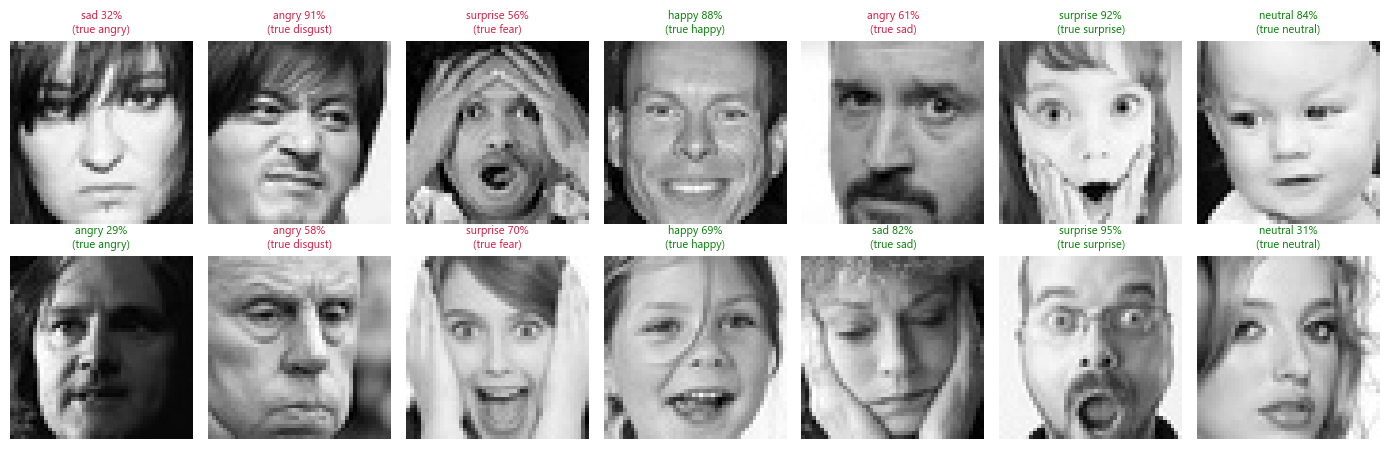

In [3]:
rng = np.random.RandomState(3)
idx = np.concatenate([rng.choice(np.where(yte == k)[0], 2, replace=False) for k in range(7)])
P = predict(Xte[idx])
fig, ax = plt.subplots(2, 7, figsize=(14, 4.6))
for a, i, p in zip(ax.T.ravel(), idx, P):
    a.imshow(Xte[i], cmap="gray"); a.axis("off")
    ok = p.argmax() == yte[i]
    a.set_title(f"{CLASSES[p.argmax()]} {p.max():.0%}\n(true {CLASSES[yte[i]]})", fontsize=8, color="green" if ok else "crimson")
plt.tight_layout(); plt.show()

## 4 · Video clips (Jack, 5 signed sentences)
MediaPipe face points -> 48×48 crop -> model -> EMA + hysteresis, the same path as the web app. Thick label = smoothed, `raw` = single frame.

In [4]:
CLIPS = sorted(Path("../data_test/team-drive/Eval-Test/Jack").glob("*.MOV"))
VID = {}
for p in CLIPS:
    t0 = time.perf_counter()
    log, thumbs = demo.run_video(p, step=3)
    VID[p.stem] = (log, thumbs)
    print(f"{p.stem[:34]:34s}", demo.stability(log), f"| {time.perf_counter()-t0:.0f}s")

ฉันสบายดี คุณสบายดี_               {'seconds': 6.8, 'raw_changes_per_s': 1.62, 'smoothed_changes_per_s': 0.0, 'raw_unknown': 0.229, 'smoothed_unknown': 0.0, 'mean_segment_s': 6.8} | 5s


พรุ่งนี้ผมจะไปเที่ยวประเทศจีน      {'seconds': 11.2, 'raw_changes_per_s': 1.61, 'smoothed_changes_per_s': 0.0, 'raw_unknown': 0.421, 'smoothed_unknown': 0.0, 'mean_segment_s': 11.2} | 6s


วันนี้ฉันนำเสนองานเรื่องภาษามือกับ {'seconds': 12.4, 'raw_changes_per_s': 0.97, 'smoothed_changes_per_s': 0.0, 'raw_unknown': 0.302, 'smoothed_unknown': 0.0, 'mean_segment_s': 12.4} | 7s


วันนี้ผมอยากเรียนภาษามือ           {'seconds': 8.2, 'raw_changes_per_s': 0.98, 'smoothed_changes_per_s': 0.49, 'raw_unknown': 0.31, 'smoothed_unknown': 0.024, 'mean_segment_s': 1.64} | 4s


สวัสดี ฉันชื่อ J ฉันชอบแมว         {'seconds': 10.8, 'raw_changes_per_s': 1.67, 'smoothed_changes_per_s': 0.37, 'raw_unknown': 0.582, 'smoothed_unknown': 0.073, 'mean_segment_s': 2.16} | 6s


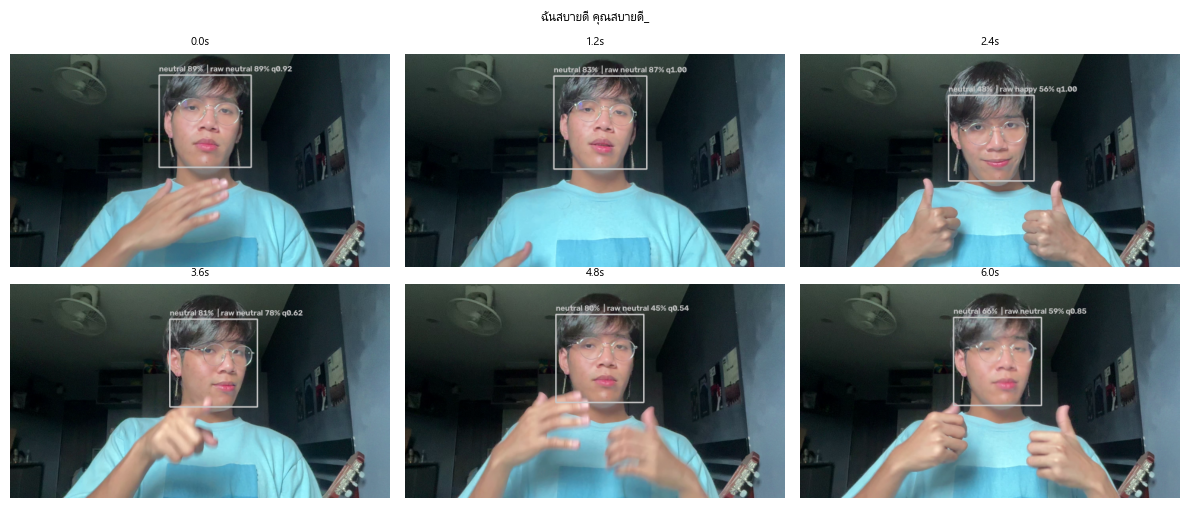

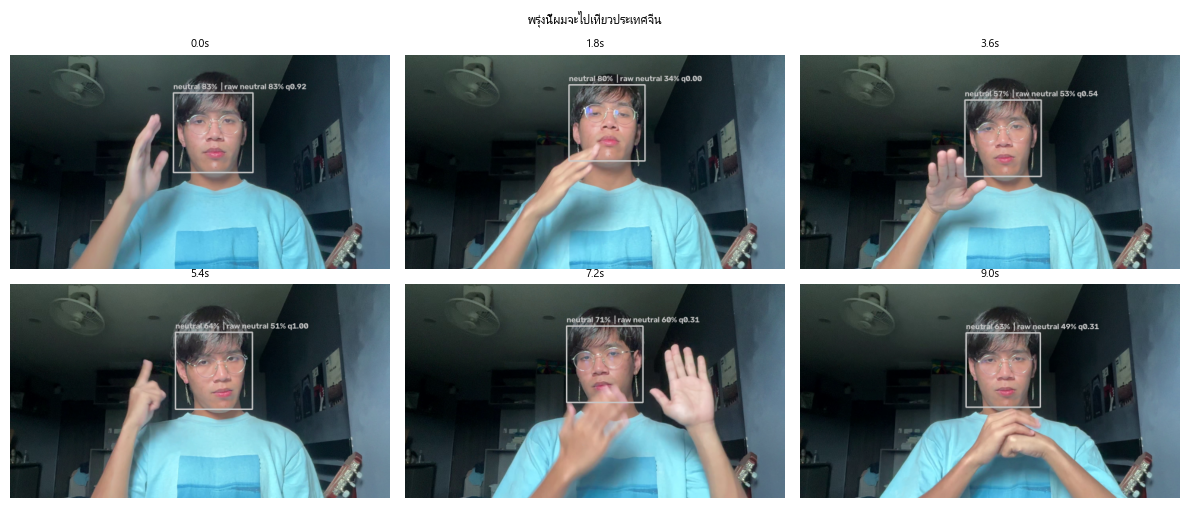

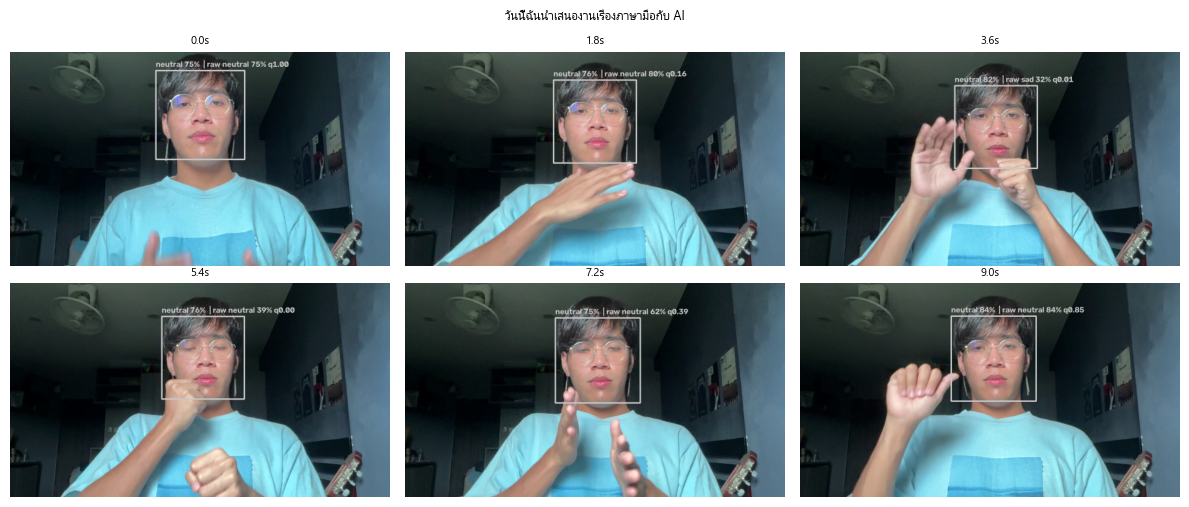

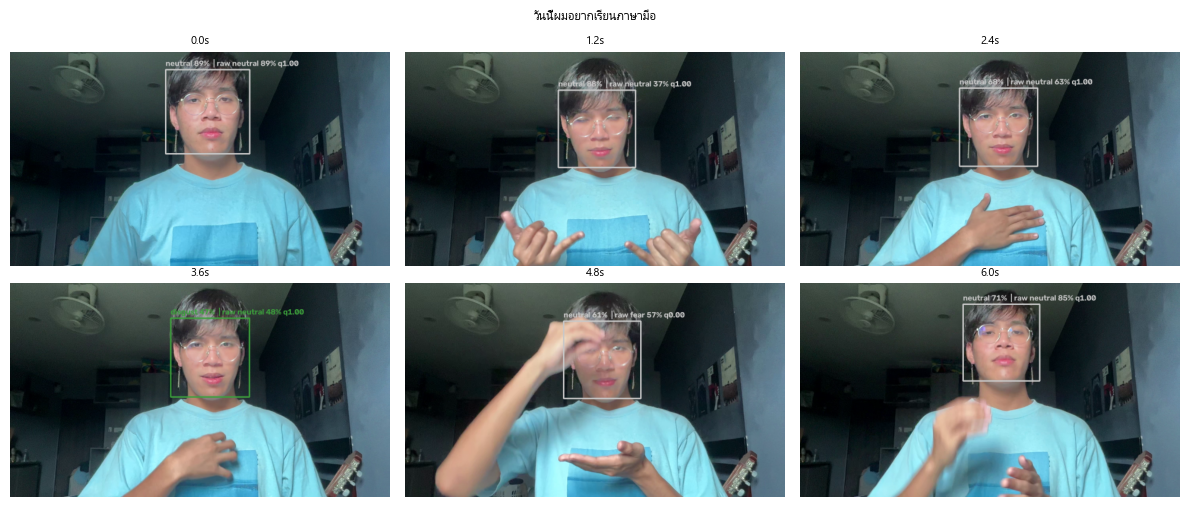

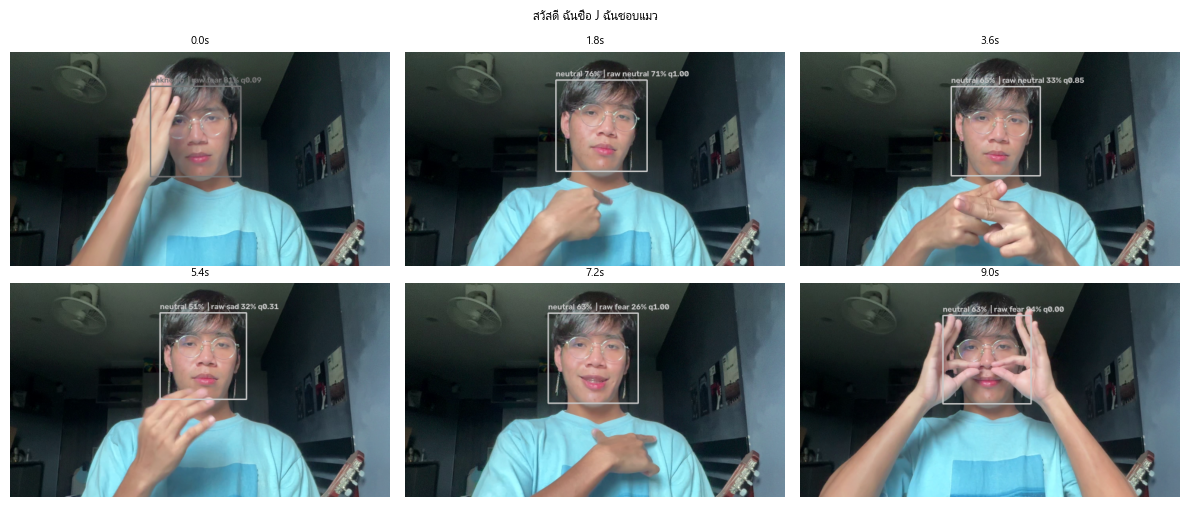

In [5]:
for name, (log, thumbs) in VID.items():
    sel = thumbs[::max(len(thumbs) // 6, 1)][:6]
    fig, ax = plt.subplots(2, 3, figsize=(12, 5.2))
    for a in ax.ravel():
        a.axis("off")
    for a, (t, im) in zip(ax.ravel(), sel):
        a.imshow(im); a.axis("off"); a.set_title(f"{t:.1f}s", fontsize=8)
    fig.suptitle(name, fontsize=9); plt.tight_layout(); plt.show()

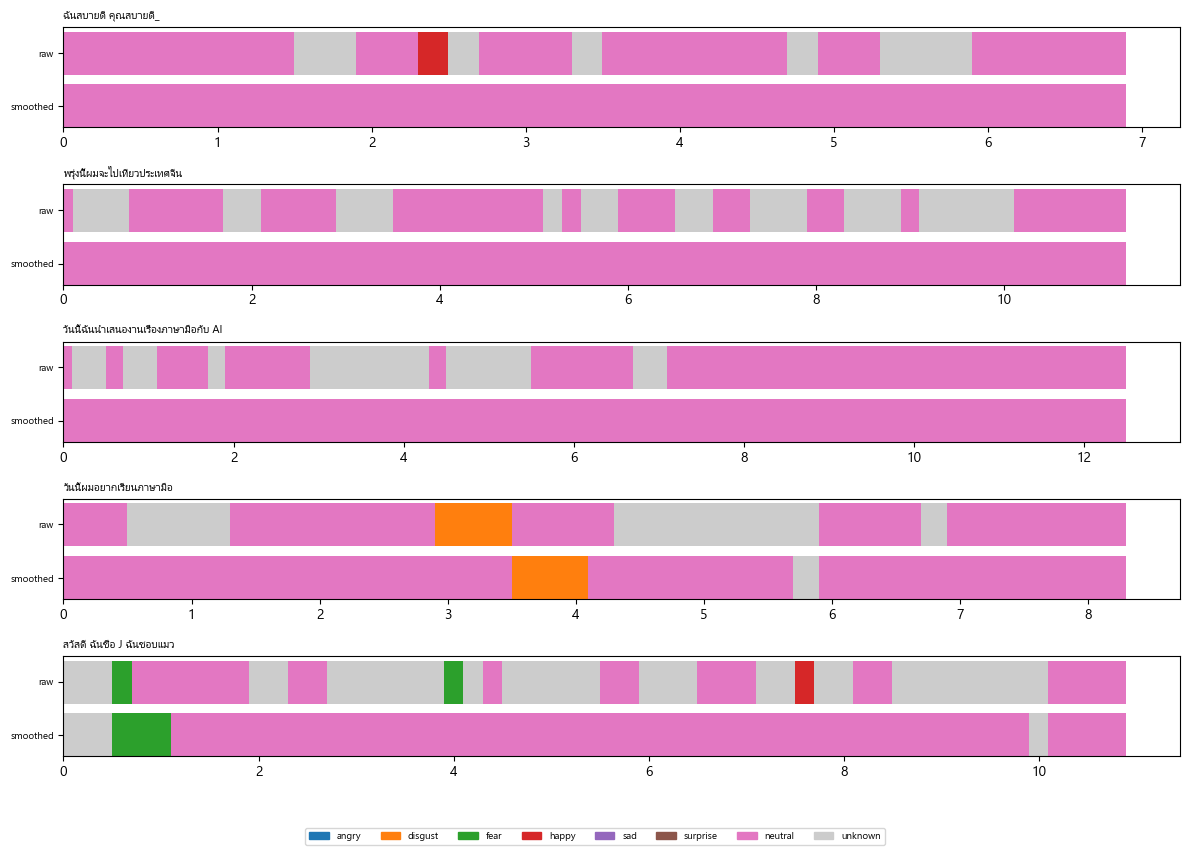

In [6]:
fig, ax = plt.subplots(len(VID), 1, figsize=(12, 1.7 * len(VID)), sharex=False)
cmap = {c: plt.cm.tab10(i) for i, c in enumerate(CLASSES)}; cmap["unknown"] = (0.8, 0.8, 0.8, 1)
for a, (name, (log, _)) in zip(np.atleast_1d(ax), VID.items()):
    for (t, _, _, raw, sm, q) in log:
        a.bar(t, 0.45, 0.2, bottom=0.55, color=cmap[raw]); a.bar(t, 0.45, 0.2, color=cmap[sm])
    a.set_yticks([0.22, 0.78]); a.set_yticklabels(["smoothed", "raw"], fontsize=7); a.set_title(name[:40], fontsize=8, loc="left"); a.set_xlim(0, None)
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in cmap.values()]
fig.legend(handles, list(cmap), ncol=8, loc="lower center", fontsize=7); plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()

## 5 · Real-time webcam
Same pipeline, live (interrupt the kernel to stop early).

In [7]:
try:
    log = demo.webcam(seconds=15)
    print(demo.stability(log))
except RuntimeError as e:
    print("webcam:", e)

459 frames in 15.7s = 29.2 fps
{}


## 6 · Evaluation — MobileNetV3-Large vs EfficientNet-B0
Same data, recipe and seed. Test = official FER2013 test (7178); clean = the 6569 test images with no twin in train. Models picked on validation Macro-F1 only.

In [8]:
import torch
from models import FerNet
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
Xva, yva = D["val"]
R = {}
for arch in ("mobilenet_v3_large", "efficientnet_b0", "resnet18"):
    ck = torch.load(f"runs/main_{arch}/best.pt", map_location="cpu")
    net = FerNet(ck["arch"], ck["res"], pretrained=False); net.load_state_dict(ck["state"]); net.eval().to(dev)
    zv, zt = ev.predict_logits(net, Xva, dev), ev.predict_logits(net, Xte, dev)
    T = ev.fit_temperature(zv, yva)
    pt = ev.softmax(zt, T)
    r = dict(net=net, T=T, p=pt, test=ev.classification(yte, pt), clean=ev.classification(yte[clean], pt[clean]), cal=ev.calibration(yte, pt),
             val=ev.classification(yva, ev.softmax(zv, T)), params=sum(p.numel() for p in net.parameters()) / 1e6,
             train_min=json.load(open(f"results/main_{arch}.json"))["train_minutes"])
    # CPU latency of the deployable graph (the winner's served file, the other exported to a temp file)
    path = MODEL / "face_fer.onnx" if arch == "efficientnet_b0" else Path("runs") / "mbv3_tmp.onnx"
    if arch != "efficientnet_b0":
        from models import export_onnx; export_onnx(net.cpu(), path)
    r["cpu_ms"] = ev.latency_ort(path, threads=2)["median_ms"]
    r["cpu_b16_ms"] = ev.latency_ort(path, batch=16, n=60, threads=2)["median_ms"]
    r["size_mb"] = Path(path).stat().st_size / 1e6
    r["gpu_ms"] = ev.latency_torch(net.to(dev), dev)["median_ms"]
    R[arch] = r
(Path("runs") / "mbv3_tmp.onnx").unlink(missing_ok=True)

In [9]:
import pandas as pd
rows = []
for arch, r in R.items():
    t, c = r["test"], r["clean"]
    rows.append(dict(model=arch, params_M=round(r["params"], 2), onnx_MB=round(r["size_mb"], 1), val_macroF1=round(r["val"]["macro_f1"], 4),
                     acc=round(t["accuracy"], 4), macroF1=round(t["macro_f1"], 4), weightedF1=round(t["weighted_f1"], 4), UAR=round(t["uar"], 4),
                     clean_acc=round(c["accuracy"], 4), clean_macroF1=round(c["macro_f1"], 4), ECE=round(r["cal"]["ece"], 4), Brier=round(r["cal"]["brier"], 4),
                     cpu_ms_b1=round(r["cpu_ms"], 1), cpu_ms_b16=round(r["cpu_b16_ms"], 1), gpu_ms_b1=round(r["gpu_ms"], 1), train_min=r["train_min"]))
pd.DataFrame(rows).set_index("model").T

model,mobilenet_v3_large,efficientnet_b0,resnet18
params_M,4.2100,4.0200,11.1800
onnx_MB,16.8000,16.1000,44.7000
val_macroF1,0.6349,0.6569,0.6600
acc,0.6743,0.6818,0.6963
macroF1,0.6625,0.6634,0.6844
weightedF1,0.6728,0.6828,0.6941
UAR,0.6640,0.6709,0.6860
clean_acc,0.6529,0.6605,0.6748
clean_macroF1,0.6273,0.6252,0.6491
ECE,0.0347,0.0301,0.0326


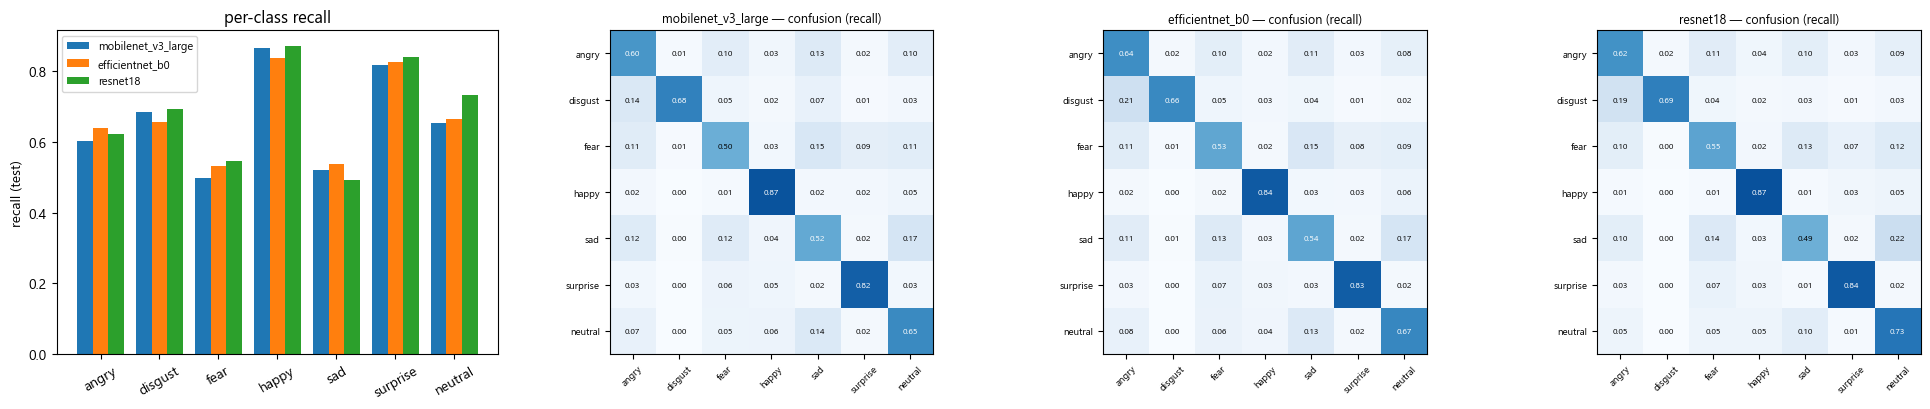

In [10]:
fig, ax = plt.subplots(1, 4, figsize=(20, 4.2))
w = 0.27; x = np.arange(7)
for j, (arch, r) in enumerate(R.items()):
    ax[0].bar(x + (j - 1) * w, [r["test"]["per_class"][c]["recall"] for c in CLASSES], w, label=arch)
ax[0].set_xticks(x); ax[0].set_xticklabels(CLASSES, rotation=30); ax[0].set_ylabel("recall (test)"); ax[0].legend(fontsize=8); ax[0].set_title("per-class recall")
for a, (arch, r) in zip(ax[1:], R.items()):
    cm = np.array(r["test"]["confusion"], float); cm /= cm.sum(1, keepdims=True)
    a.imshow(cm, cmap="Blues", vmin=0, vmax=1); a.set_title(f"{arch} — confusion (recall)", fontsize=9)
    a.set_xticks(range(7)); a.set_xticklabels(CLASSES, rotation=45, fontsize=7); a.set_yticks(range(7)); a.set_yticklabels(CLASSES, fontsize=7)
    for i in range(7):
        for k in range(7):
            a.text(k, i, f"{cm[i, k]:.2f}", ha="center", va="center", fontsize=6, color="white" if cm[i, k] > 0.5 else "black")
plt.tight_layout(); plt.show()

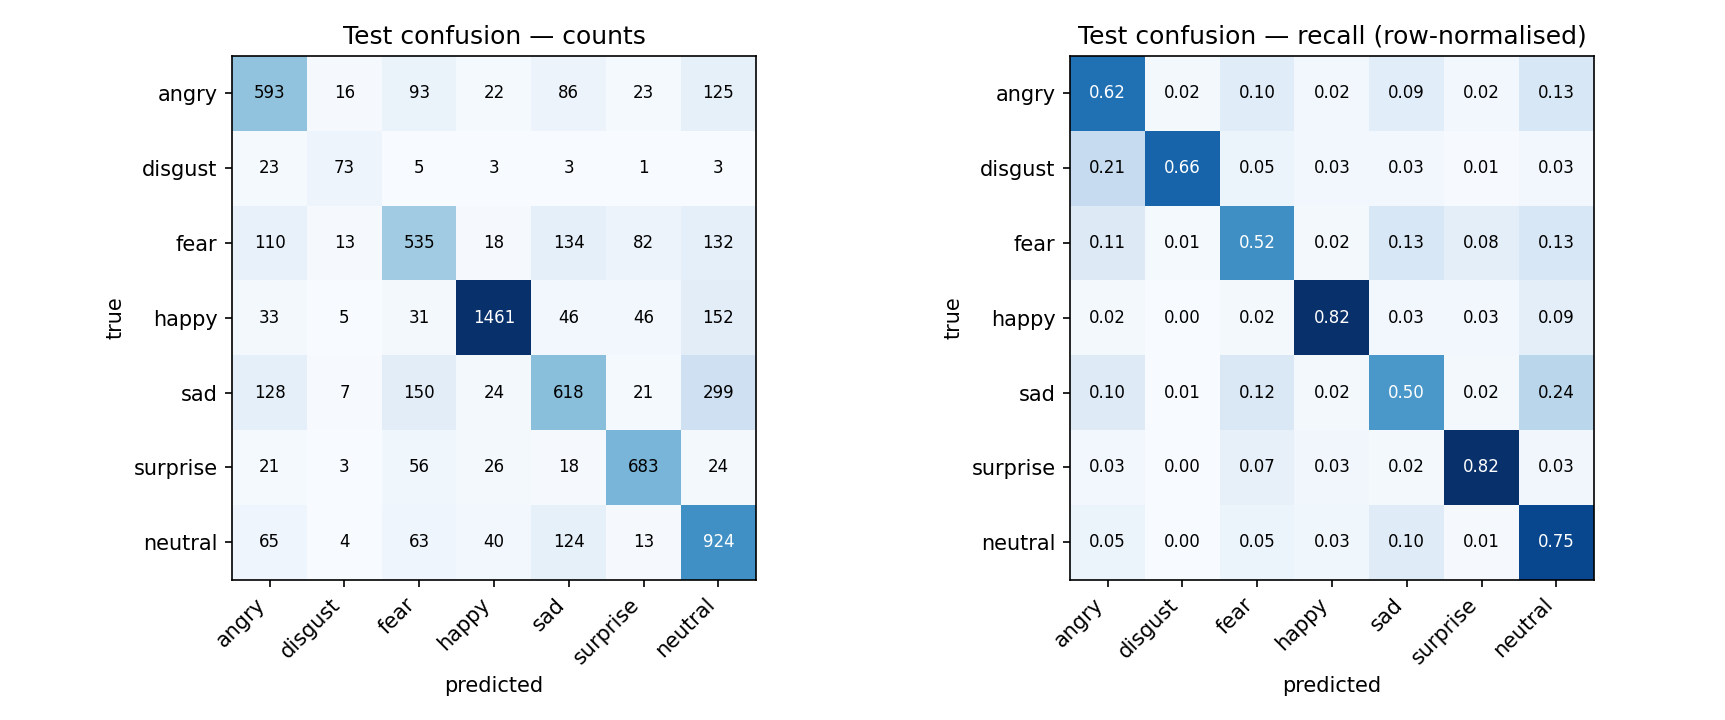

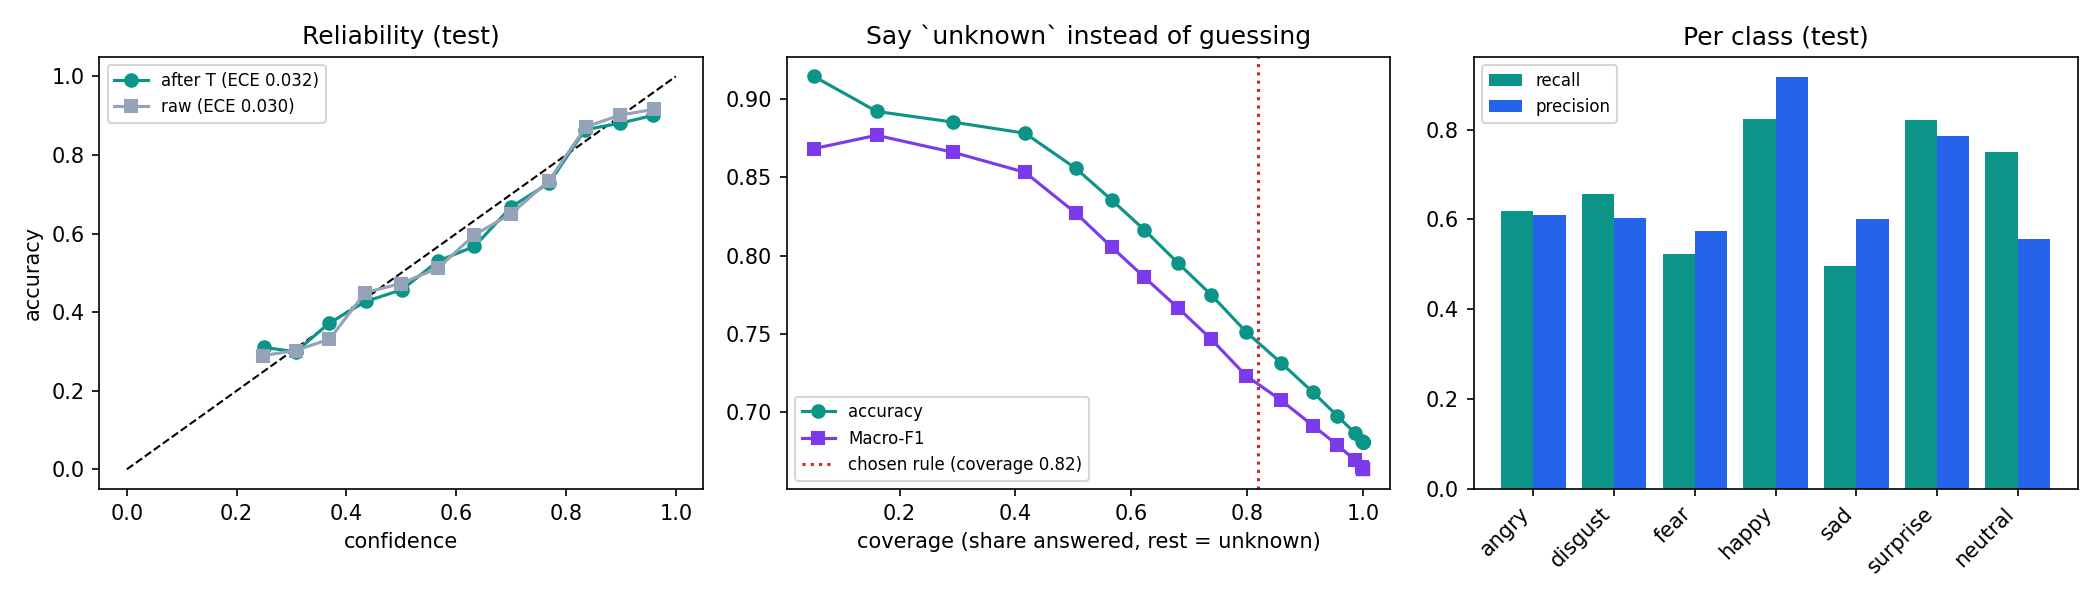

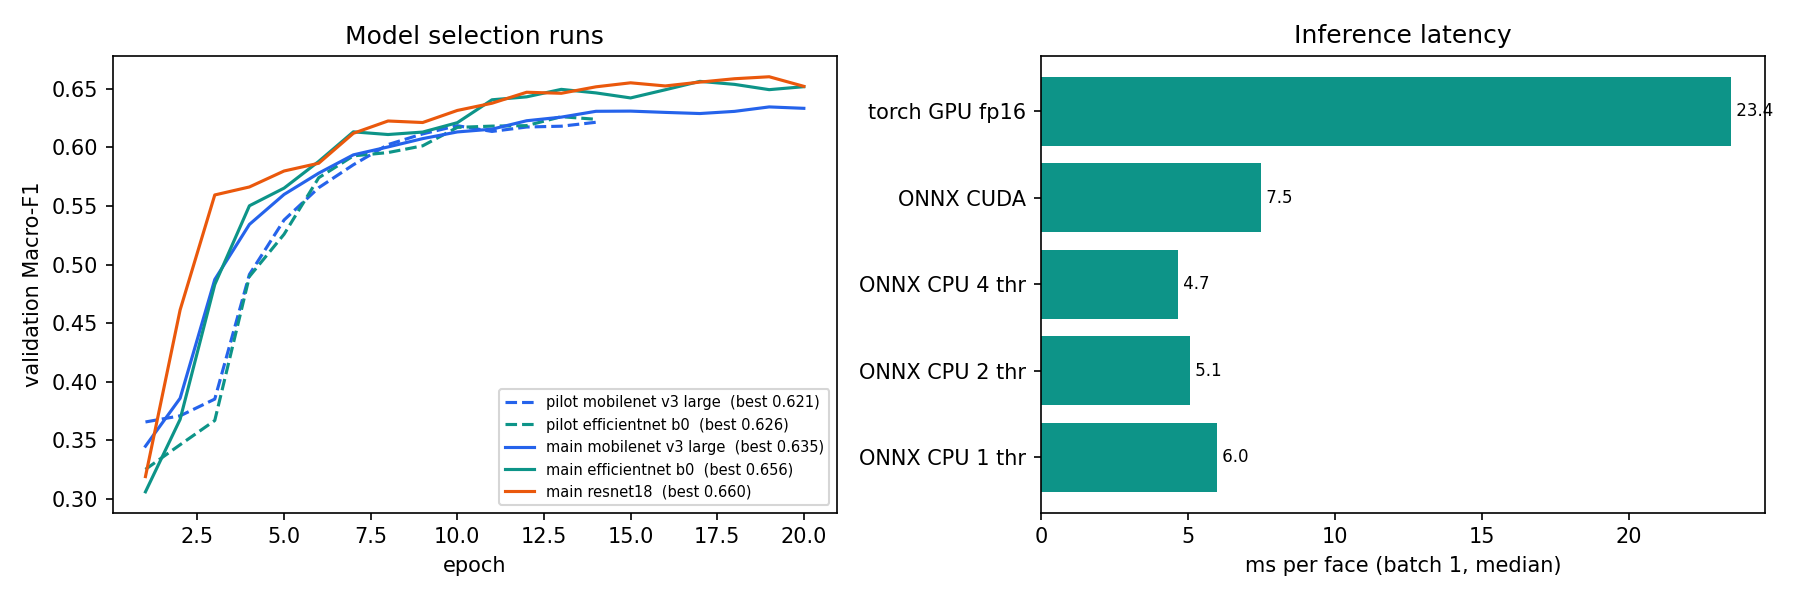

In [11]:
for f in ("confusion", "calibration_selective", "selection_latency"):
    display(Image(f"figures/{f}.png"))

## 7 · Real signer faces (18 clips: Boom, Jack, Pitty)
No expression labels exist for these clips: this is a small hand-judged set (3 smiles; ambiguous frames left out; every other usable frame counted as neutral) that shows whether the branch is stable or over-reacts. `real_check.py` reproduces it; ResNet-18 numbers below come from the same check run before its bundle was dropped.

In [12]:
rc = json.load(open("results/real_check.json", encoding="utf-8"))["models"]["efficientnetb0"]
print("EfficientNet-B0, shown label (after unknown rule + smoother) on the frames judged neutral:")
display(pd.DataFrame(rc["stability"]).drop("per_signer").T)
print({k: v for k, v in rc["stability"]["shipped"]["per_signer"].items()})
print("\nexpressive real frames (model only, no prior):")
for e in rc["expressive_frames"]:
    print("  ", e)
print("\nResNet-18 on the same frames has neutral as its top choice for the smiles, the question brows and the sad line (0.33-0.70), i.e. it is stable but not sensitive.")

EfficientNet-B0, shown label (after unknown rule + smoother) on the frames judged neutral:


,prior,raw_answered_on_neutral,shown_neutral,shown_wrong_expression,shown_unknown,smiles_shown_happy
no prior,{},0.556,0.646,0.125,0.23,3/3
shipped,{'neutral': 0.6},0.704,0.821,0.066,0.113,2/3


{'Boom': {'shown_neutral': 0.825, 'wrong': 0.087}, 'Jack': {'shown_neutral': 0.961, 'wrong': 0.0}, 'Pitty': {'shown_neutral': 0.675, 'wrong': 0.104}}

expressive real frames (model only, no prior):
   {'clip': 12, 't': 1.5, 'what': 'smile', 'top': [['happy', 0.54], ['neutral', 0.17]]}
   {'clip': 15, 't': 0.0, 'what': 'smile', 'top': [['happy', 0.58], ['fear', 0.15]]}
   {'clip': 15, 't': 1.5, 'what': 'smile', 'top': [['happy', 0.3], ['neutral', 0.27]]}
   {'clip': 3, 't': 10.6, 'what': 'question brows', 'top': [['surprise', 0.59], ['fear', 0.11]]}
   {'clip': 5, 't': 7.5, 'what': 'question brows', 'top': [['surprise', 0.67], ['neutral', 0.11]]}
   {'clip': 5, 't': 9.0, 'what': 'question brows', 'top': [['surprise', 0.74], ['happy', 0.07]]}
   {'clip': 0, 't': 0.0, 'what': 'sad line', 'top': [['sad', 0.42], ['neutral', 0.34]]}
   {'clip': 0, 't': 1.5, 'what': 'sad line', 'top': [['sad', 0.32], ['neutral', 0.28]]}
   {'clip': 9, 't': 3.2, 'what': 'head back', 'top': [['disgust', 0.89], 

In [13]:
fin = json.load(open("results/final_eval.json"))
print("deployed model:", MODEL.name, "| thresholds:", fin["thresholds"], "| T =", fin["temperature"])
print("test  acc %.4f  macroF1 %.4f  UAR %.4f | flip-TTA acc %.4f macroF1 %.4f" % (fin["test"]["accuracy"], fin["test"]["macro_f1"], fin["test"]["uar"], fin["test_flip_tta"]["accuracy"], fin["test_flip_tta"]["macro_f1"]))
u = fin["test_with_unknown"]; print("with the unknown rule: coverage %.3f, accuracy on answered %.3f, macroF1 on answered %.3f" % (u["coverage"], u["answered"]["accuracy"], u["answered"]["macro_f1"]))
print("ONNX vs torch parity:", fin["parity"]); print({k: v["median_ms"] for k, v in fin["efficiency"].items() if isinstance(v, dict) and "median_ms" in v})

deployed model: face-model-efficientnetb0-v1 | thresholds: {'min_conf': 0.48, 'min_margin': 0.1, 'min_quality': 0.25} | T = 1.0
test  acc 0.6808  macroF1 0.6633  UAR 0.6699 | flip-TTA acc 0.6875 macroF1 0.6711
with the unknown rule: coverage 0.819, accuracy on answered 0.745, macroF1 on answered 0.717
ONNX vs torch parity: {'max_abs_logit_diff_onnx_vs_torch_cpu': 1.0371208190917969e-05, 'argmax_agreement': 1.0, 'max_abs_logit_diff_vs_gpu_fp16': 0.030731916427612305, 'argmax_agreement_vs_gpu_fp16': 0.994140625}
{'onnx_cpu_1thread_b1': 5.999349999910919, 'onnx_cpu_2thread_b1': 5.070349998277379, 'onnx_cpu_4thread_b1': 4.670900001656264, 'onnx_cpu_2thread_b16': 65.06439999793656, 'torch_gpu_fp16_b1': 23.448950003512437, 'torch_gpu_fp16_b32': 23.626049998711096, 'onnx_cuda_b1': 7.492949996958487}
